In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sbhatti/financial-sentiment-analysis")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'financial-sentiment-analysis' dataset.
Path to dataset files: /kaggle/input/financial-sentiment-analysis


In [ ]:
import os

# The 'path' variable is from your previous cell
# Let's list the files inside that directory
file_list = os.listdir(path)
print("Files in the dataset directory:", file_list)

# Find the name of the CSV file
csv_file_name = [f for f in file_list if f.endswith('.csv')][0]
print("CSV file found:", csv_file_name)

Files in the dataset directory: ['data.csv', '.nfs0000000037d5cd1400000077']
CSV file found: data.csv


In [ ]:
import pandas as pd

# Construct the full path to the data file
full_file_path = os.path.join(path, csv_file_name)

# Load the data into a DataFrame
df = pd.read_csv(full_file_path)

print("\nDataset loaded successfully!")
print("DataFrame Head:")
print(df.head())


Dataset loaded successfully!
DataFrame Head:
                                            Sentence Sentiment
0  The GeoSolutions technology will leverage Bene...  positive
1  $ESI on lows, down $1.50 to $2.50 BK a real po...  negative
2  For the last quarter of 2010 , Componenta 's n...  positive
3  According to the Finnish-Russian Chamber of Co...   neutral
4  The Swedish buyout firm has sold its remaining...   neutral


In [ ]:
# Display a concise summary of the DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5842 entries, 0 to 5841
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Sentence   5842 non-null   object
 1   Sentiment  5842 non-null   object
dtypes: object(2)
memory usage: 91.4+ KB


Class Distribution:
Sentiment
neutral     3130
positive    1852
negative     860
Name: count, dtype: int64


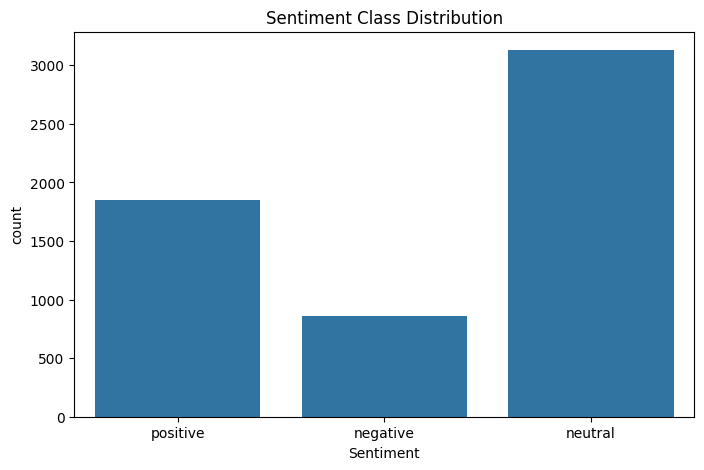

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Display the count of each class in the 'Sentiment' column
print("Class Distribution:")
print(df['Sentiment'].value_counts())

# Visualize the distribution
plt.figure(figsize=(8, 5))
sns.countplot(x='Sentiment', data=df)
plt.title('Sentiment Class Distribution')
plt.show()

In [ ]:
# Rename 'Sentence' to 'text' and 'Sentiment' to 'label'
df = df.rename(columns={'Sentence': 'text', 'Sentiment': 'label'})

# Map the string labels to numbers (0=negative, 1=neutral, 2=positive)
label_map = {'negative': 0, 'neutral': 1, 'positive': 2}
df['label'] = df['label'].map(label_map)

print("Columns renamed and labels mapped to integers:")
print(df.head())

Columns renamed and labels mapped to integers:
                                                text  label
0  The GeoSolutions technology will leverage Bene...      2
1  $ESI on lows, down $1.50 to $2.50 BK a real po...      0
2  For the last quarter of 2010 , Componenta 's n...      2
3  According to the Finnish-Russian Chamber of Co...      1
4  The Swedish buyout firm has sold its remaining...      1


In [ ]:
import re
import nltk
from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split

# --- Clean the Text Data ---
try:
    stop_words = set(stopwords.words('english'))
except LookupError:
    nltk.download('stopwords')
    stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = text.lower()
    words = text.split()
    words = [word for word in words if word not in stop_words]
    return ' '.join(words)

print("\nCleaning text data...")
df['cleaned_text'] = df['text'].apply(clean_text)
print("Cleaning complete.")

# --- Split the Data ---
X = df['cleaned_text']
y = df['label']

# Use stratify=y to maintain class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\nData splitting complete.")

[nltk_data] Downloading package stopwords to /root/nltk_data...



Cleaning text data...
Cleaning complete.

Data splitting complete.


[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch

# Calculate the weights
class_labels = np.unique(y_train)
class_weights = compute_class_weight(class_weight='balanced', classes=class_labels, y=y_train)

# Convert to a PyTorch tensor
weights = torch.tensor(class_weights, dtype=torch.float).to('cuda')
weights

tensor([2.2641, 0.6222, 1.0514], device='cuda:0')

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Define the baseline pipeline without SMOTE
baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('classifier', LogisticRegression(random_state=42, solver='liblinear'))
])

# Train the baseline pipeline
print("Training the baseline Logistic Regression model (without SMOTE)...")
baseline_pipeline.fit(X_train, y_train)
print("Training complete.")

# Make predictions
y_pred_baseline = baseline_pipeline.predict(X_test)

# Evaluate the baseline model
print("\n--- Baseline Model Performance (Without SMOTE) ---")
print(classification_report(y_test, y_pred_baseline, target_names=['negative', 'neutral', 'positive']))

Training the baseline Logistic Regression model (without SMOTE)...
Training complete.

--- Baseline Model Performance (Without SMOTE) ---
              precision    recall  f1-score   support

    negative       0.48      0.13      0.20       215
     neutral       0.67      0.92      0.77       783
    positive       0.76      0.54      0.63       463

    accuracy                           0.68      1461
   macro avg       0.64      0.53      0.53      1461
weighted avg       0.67      0.68      0.64      1461



In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, accuracy_score

# 1. Define the steps of the pipeline
# Step 1: TF-IDF Vectorizer
# Step 2: SMOTE for oversampling the minority classes
# Step 3: Logistic Regression model
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('smote', SMOTE(random_state=42)),
    ('classifier', LogisticRegression(random_state=42, solver='liblinear'))
])

# 2. Train the entire pipeline on the training data
print("Training the SMOTE pipeline with Logistic Regression...")
pipeline.fit(X_train, y_train)
print("Training complete.")

# 3. Make predictions on the test set
y_pred = pipeline.predict(X_test)

# 4. Evaluate the model's performance
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAccuracy: {accuracy:.4f}")

# Print a detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['negative', 'neutral', 'positive']))

Training the SMOTE pipeline with Logistic Regression...
Training complete.

Accuracy: 0.6674

Classification Report:
              precision    recall  f1-score   support

    negative       0.35      0.47      0.40       215
     neutral       0.76      0.73      0.74       783
    positive       0.73      0.65      0.69       463

    accuracy                           0.67      1461
   macro avg       0.61      0.62      0.61      1461
weighted avg       0.69      0.67      0.68      1461



In [ ]:
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

# Define the baseline pipeline for SVC
svc_baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('classifier', LinearSVC(random_state=42, dual=False))
])

# Train and evaluate
print("Training baseline SVC (without SMOTE)...")
svc_baseline_pipeline.fit(X_train, y_train)
y_pred_svc_baseline = svc_baseline_pipeline.predict(X_test)
print("\n--- Baseline SVC Performance (Without SMOTE) ---")
print(classification_report(y_test, y_pred_svc_baseline, target_names=['negative', 'neutral', 'positive']))

Training baseline SVC (without SMOTE)...

--- Baseline SVC Performance (Without SMOTE) ---
              precision    recall  f1-score   support

    negative       0.27      0.20      0.23       215
     neutral       0.71      0.79      0.75       783
    positive       0.74      0.68      0.71       463

    accuracy                           0.67      1461
   macro avg       0.57      0.56      0.56      1461
weighted avg       0.65      0.67      0.66      1461



In [ ]:
from imblearn.pipeline import Pipeline as ImblearnPipeline
from imblearn.over_sampling import SMOTE

# Define the imblearn pipeline for SVC
svc_smote_pipeline = ImblearnPipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('smote', SMOTE(random_state=42)),
    ('classifier', LinearSVC(random_state=42, dual=False))
])

# Train and evaluate
print("Training SVC with SMOTE...")
svc_smote_pipeline.fit(X_train, y_train)
y_pred_svc_smote = svc_smote_pipeline.predict(X_test)
print("\n--- SVC Performance (With SMOTE) ---")
print(classification_report(y_test, y_pred_svc_smote, target_names=['negative', 'neutral', 'positive']))

Training SVC with SMOTE...

--- SVC Performance (With SMOTE) ---
              precision    recall  f1-score   support

    negative       0.29      0.38      0.33       215
     neutral       0.75      0.70      0.73       783
    positive       0.72      0.70      0.71       463

    accuracy                           0.65      1461
   macro avg       0.59      0.59      0.59      1461
weighted avg       0.67      0.65      0.66      1461



In [ ]:
from xgboost import XGBClassifier

# Define the baseline pipeline for XGBoost
xgb_baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('classifier', XGBClassifier(random_state=42, n_jobs=-1))
])

# Train and evaluate
print("Training baseline XGBoost (without SMOTE)...")
xgb_baseline_pipeline.fit(X_train, y_train)
y_pred_xgb_baseline = xgb_baseline_pipeline.predict(X_test)
print("\n--- Baseline XGBoost Performance (Without SMOTE) ---")
print(classification_report(y_test, y_pred_xgb_baseline, target_names=['negative', 'neutral', 'positive']))

Training baseline XGBoost (without SMOTE)...

--- Baseline XGBoost Performance (Without SMOTE) ---
              precision    recall  f1-score   support

    negative       0.28      0.15      0.20       215
     neutral       0.65      0.85      0.74       783
    positive       0.78      0.53      0.63       463

    accuracy                           0.65      1461
   macro avg       0.57      0.51      0.52      1461
weighted avg       0.63      0.65      0.62      1461



In [ ]:
# Define the imblearn pipeline for XGBoost
xgb_smote_pipeline = ImblearnPipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(random_state=42, n_jobs=-1))
])

# Train and evaluate
print("Training XGBoost with SMOTE...")
xgb_smote_pipeline.fit(X_train, y_train)
y_pred_xgb_smote = xgb_smote_pipeline.predict(X_test)
print("\n--- XGBoost Performance (With SMOTE) ---")
print(classification_report(y_test, y_pred_xgb_smote, target_names=['negative', 'neutral', 'positive']))

Training XGBoost with SMOTE...

--- XGBoost Performance (With SMOTE) ---
              precision    recall  f1-score   support

    negative       0.33      0.30      0.31       215
     neutral       0.67      0.80      0.73       783
    positive       0.75      0.54      0.63       463

    accuracy                           0.64      1461
   macro avg       0.58      0.55      0.56      1461
weighted avg       0.64      0.64      0.64      1461



In [ ]:
from sklearn.naive_bayes import MultinomialNB

# Define the baseline pipeline for Naive Bayes
nb_baseline_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('classifier', MultinomialNB())
])

# Train and evaluate
print("Training baseline Naive Bayes (without SMOTE)...")
nb_baseline_pipeline.fit(X_train, y_train)
y_pred_nb_baseline = nb_baseline_pipeline.predict(X_test)
print("\n--- Baseline Naive Bayes Performance (Without SMOTE) ---")
print(classification_report(y_test, y_pred_nb_baseline, target_names=['negative', 'neutral', 'positive']))

Training baseline Naive Bayes (without SMOTE)...

--- Baseline Naive Bayes Performance (Without SMOTE) ---
              precision    recall  f1-score   support

    negative       0.62      0.04      0.07       215
     neutral       0.67      0.95      0.78       783
    positive       0.71      0.51      0.59       463

    accuracy                           0.68      1461
   macro avg       0.66      0.50      0.48      1461
weighted avg       0.67      0.68      0.62      1461



In [ ]:
# Define the imblearn pipeline for Naive Bayes
nb_smote_pipeline = ImblearnPipeline([
    ('tfidf', TfidfVectorizer(max_features=5000)),
    ('smote', SMOTE(random_state=42)),
    ('classifier', MultinomialNB())
])

# Train and evaluate
print("Training Naive Bayes with SMOTE...")
nb_smote_pipeline.fit(X_train, y_train)
y_pred_nb_smote = nb_smote_pipeline.predict(X_test)
print("\n--- Naive Bayes Performance (With SMOTE) ---")
print(classification_report(y_test, y_pred_nb_smote, target_names=['negative', 'neutral', 'positive']))

Training Naive Bayes with SMOTE...

--- Naive Bayes Performance (With SMOTE) ---
              precision    recall  f1-score   support

    negative       0.32      0.58      0.42       215
     neutral       0.77      0.68      0.72       783
    positive       0.69      0.59      0.63       463

    accuracy                           0.63      1461
   macro avg       0.60      0.61      0.59      1461
weighted avg       0.68      0.63      0.65      1461



In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

# List of models and their predictions
models = {
    "Logistic Regression": (y_pred_baseline, y_pred), # (Without SMOTE, With SMOTE)
    "LinearSVC": (y_pred_svc_baseline, y_pred_svc_smote),
    "XGBoost": (y_pred_xgb_baseline, y_pred_xgb_smote),
    "Naive Bayes": (y_pred_nb_baseline, y_pred_nb_smote)
}

# Create a list to store the results
results_list = []

for model_name, (pred_baseline, pred_smote) in models.items():
    # --- Without SMOTE ---
    report_baseline = classification_report(y_test, pred_baseline, output_dict=True)
    results_list.append({
        "Model": model_name,
        "Method": "Without SMOTE",
        "Weighted F1-Score": report_baseline['weighted avg']['f1-score'],
        "Negative Recall": report_baseline['0']['recall'] # 0 is the 'negative' class
    })

    # --- With SMOTE ---
    report_smote = classification_report(y_test, pred_smote, output_dict=True)
    results_list.append({
        "Model": model_name,
        "Method": "With SMOTE",
        "Weighted F1-Score": report_smote['weighted avg']['f1-score'],
        "Negative Recall": report_smote['0']['recall']
    })

# Create the final DataFrame
comparison_df = pd.DataFrame(results_list)

print("--- Final Model Performance Comparison ---")
print(comparison_df.round(4))

--- Final Model Performance Comparison ---
                 Model         Method  Weighted F1-Score  Negative Recall
0  Logistic Regression  Without SMOTE             0.6424           0.1256
1  Logistic Regression     With SMOTE             0.6758           0.4744
2            LinearSVC  Without SMOTE             0.6588           0.1953
3            LinearSVC     With SMOTE             0.6616           0.3814
4              XGBoost  Without SMOTE             0.6232           0.1535
5              XGBoost     With SMOTE             0.6353           0.2977
6          Naive Bayes  Without SMOTE             0.6179           0.0372
7          Naive Bayes     With SMOTE             0.6478           0.5767


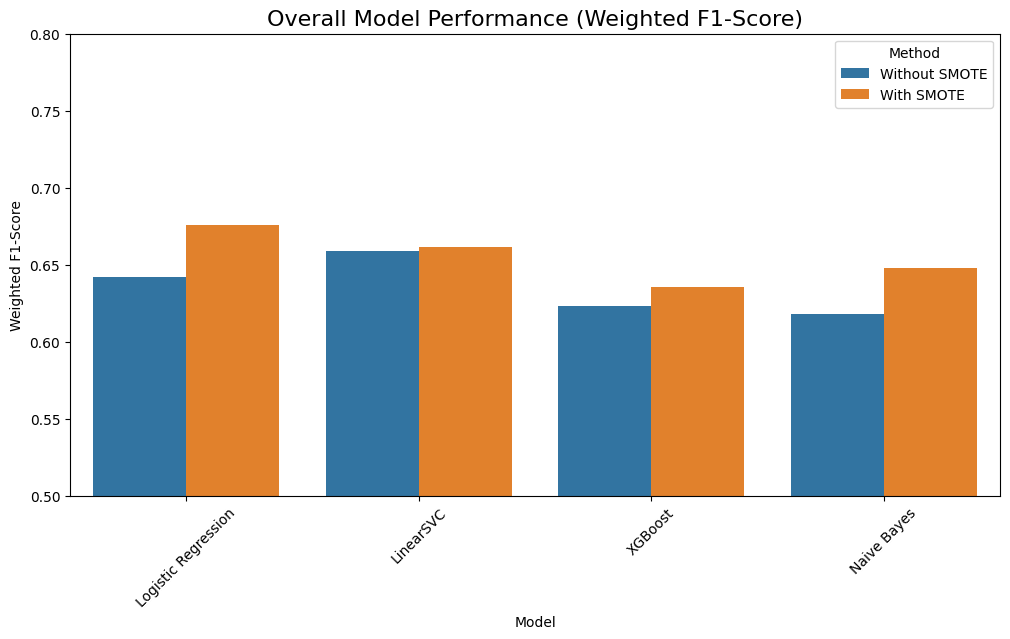

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Plot 1: Overall F1-Score ---
plt.figure(figsize=(12, 6))
sns.barplot(data=comparison_df, x="Model", y="Weighted F1-Score", hue="Method")
plt.title("Overall Model Performance (Weighted F1-Score)", fontsize=16)
plt.xticks(rotation=45)
plt.ylim(0.5, 0.8) # Adjust ylim for better visibility
plt.show()




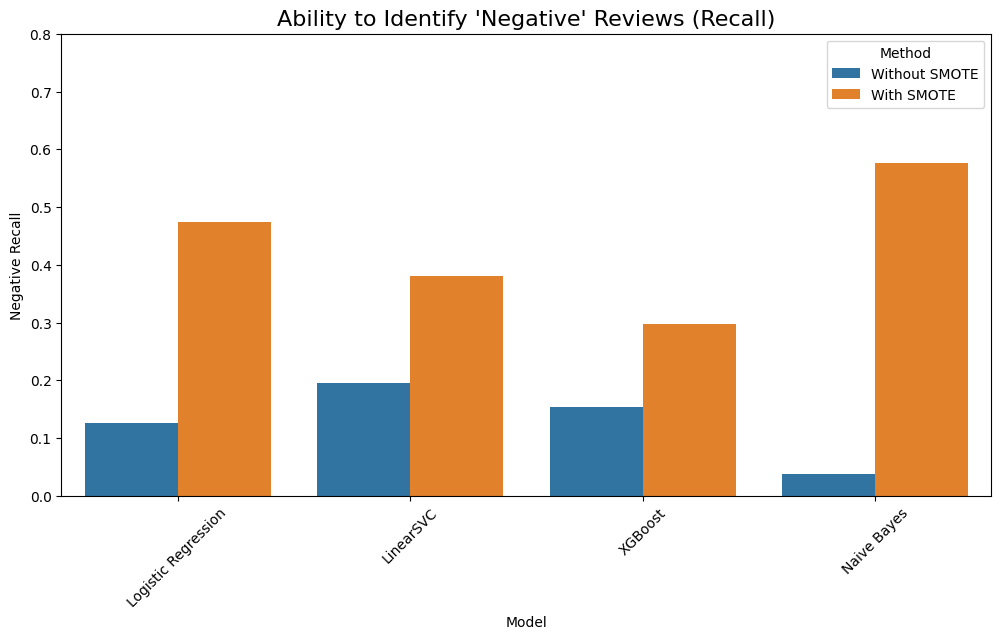

In [ ]:
# --- Plot 2: Minority Class Recall ---
plt.figure(figsize=(12, 6))
sns.barplot(data=comparison_df, x="Model", y="Negative Recall", hue="Method")
plt.title("Ability to Identify 'Negative' Reviews (Recall)", fontsize=16)
plt.xticks(rotation=45)
plt.ylim(0, 0.8) # Adjust ylim for better visibility
plt.show()

In [ ]:
from transformers import AutoTokenizer
import torch
from datasets import Dataset

# 1. Load the tokenizer for DistilBERT
# This tokenizer knows exactly how to convert text into the format DistilBERT expects
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 2. Tokenize our training and testing text
# We use the original X_train and X_test text splits
train_encodings = tokenizer(list(X_train), truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(list(X_test), truncation=True, padding=True, max_length=128)

# 3. Create a PyTorch Dataset object
# This is the format the Hugging Face Trainer needs
train_dataset = Dataset.from_dict({
    'input_ids': train_encodings['input_ids'],
    'attention_mask': train_encodings['attention_mask'],
    'labels': list(y_train)
})

test_dataset = Dataset.from_dict({
    'input_ids': test_encodings['input_ids'],
    'attention_mask': test_encodings['attention_mask'],
    'labels': list(y_test)
})

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [ ]:
from transformers import Trainer
import torch

class CustomTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        # forward pass
        outputs = model(**inputs)
        logits = outputs.get('logits')
        # compute custom loss
        loss_fct = torch.nn.CrossEntropyLoss(weight=weights)
        # Correctly reshape the logits tensor
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [ ]:
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments
from sklearn.metrics import classification_report

# 1. Load the pre-trained DistilBERT model
# We tell it we have 3 labels (negative, neutral, positive)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)

# 2. Define the training settings
# These are the hyperparameters for our fine-tuning process
training_args = TrainingArguments(
    output_dir='./results',          # directory to save model checkpoints
    num_train_epochs=2,              # number of training epochs
    per_device_train_batch_size=16,  # batch size for training
    per_device_eval_batch_size=64,   # batch size for evaluation
    warmup_steps=50,                # number of warmup steps for learning rate scheduler
    weight_decay=0.01,               # strength of weight decay
    logging_dir='./logs',            # directory for storing logs
    logging_steps=10,
)

# 3. Create the Trainer object
# This object brings together the model, settings, and datasets
trainer = CustomTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

# 4. Fine-tune the model!
# This single command handles the entire training process
print("Fine-tuning the Transformer model...")
trainer.train()
print("Training complete.")

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Fine-tuning the Transformer model...


/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: mandiramajhi7 (mandiramajhi7-ai) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Step,Training Loss
10,1.087300
20,1.092800
30,1.098800
40,1.074200
50,1.046800
60,0.992600
70,0.877500
80,0.851500
90,0.858200
100,0.809100


Training complete.


In [ ]:
import numpy as np

# Get predictions on the test set
predictions = trainer.predict(test_dataset)
y_pred_transformer = np.argmax(predictions.predictions, axis=-1)

# Display the final classification report
print("\n--- Weighted Transformer Model Performance ---")
print(classification_report(y_test, y_pred_transformer, target_names=['negative', 'neutral', 'positive']))


--- Weighted Transformer Model Performance ---
              precision    recall  f1-score   support

    negative       0.45      0.71      0.55       215
     neutral       0.87      0.70      0.78       783
    positive       0.75      0.80      0.78       463

    accuracy                           0.73      1461
   macro avg       0.69      0.74      0.70      1461
weighted avg       0.77      0.73      0.74      1461



In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

# This assumes all your previous predictions are still in memory
# Let's recreate the list and add the Transformer's results

# We'll need the classification report for the Transformer as a dictionary
report_transformer = classification_report(y_test, y_pred_transformer, output_dict=True)

# Add the Transformer's results to our list
results_list.append({
    "Model": "DistilBERT",
    "Method": "Fine-Tuning",
    "Weighted F1-Score": report_transformer['weighted avg']['f1-score'],
    "Negative Recall": report_transformer['0']['recall'] # 0 is the 'negative' class
})

# Create the final, all-inclusive DataFrame
final_comparison_df = pd.DataFrame(results_list)

print("--- Final Comprehensive Model Performance ---")
print(final_comparison_df.round(4).sort_values(by="Weighted F1-Score", ascending=False))

--- Final Comprehensive Model Performance ---
                 Model         Method  Weighted F1-Score  Negative Recall
8           DistilBERT    Fine-Tuning             0.7442           0.7116
1  Logistic Regression     With SMOTE             0.6758           0.4744
3            LinearSVC     With SMOTE             0.6616           0.3814
2            LinearSVC  Without SMOTE             0.6588           0.1953
7          Naive Bayes     With SMOTE             0.6478           0.5767
0  Logistic Regression  Without SMOTE             0.6424           0.1256
5              XGBoost     With SMOTE             0.6353           0.2977
4              XGBoost  Without SMOTE             0.6232           0.1535
6          Naive Bayes  Without SMOTE             0.6179           0.0372


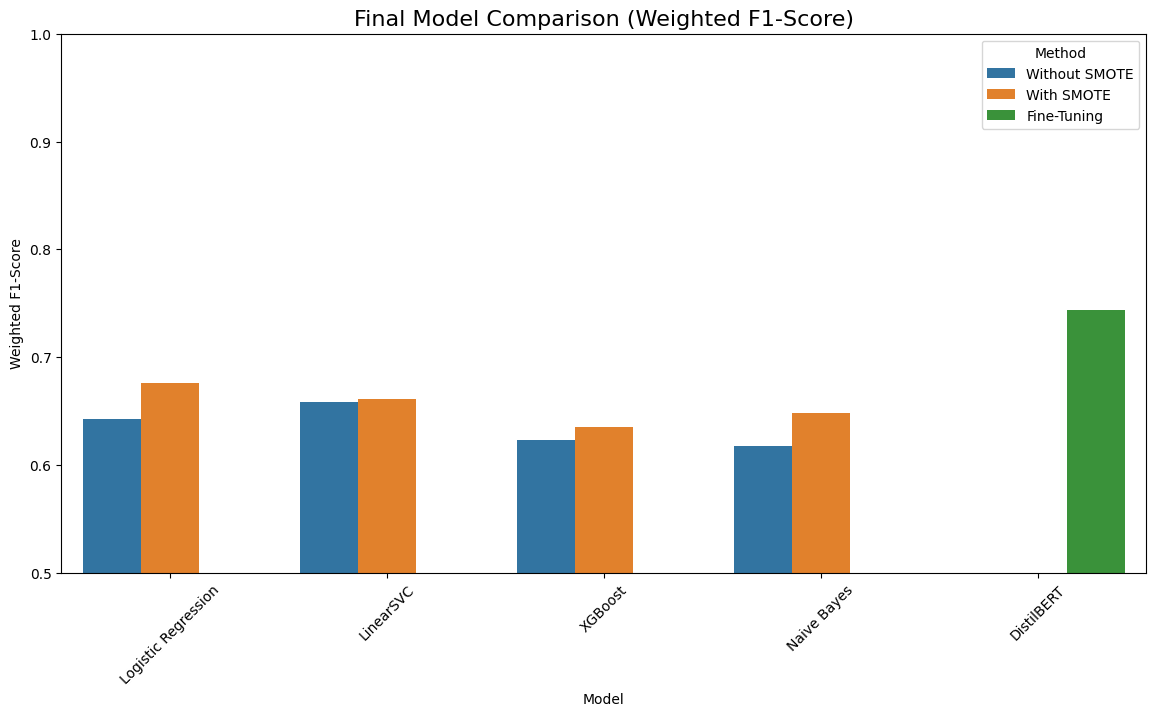

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Plot the Final F1-Score Comparison ---
plt.figure(figsize=(14, 7))
sns.barplot(data=final_comparison_df, x="Model", y="Weighted F1-Score", hue="Method")
plt.title("Final Model Comparison (Weighted F1-Score)", fontsize=16)
plt.xticks(rotation=45)
plt.ylim(0.5, 1.0) # Adjust ylim for better visibility
plt.show()


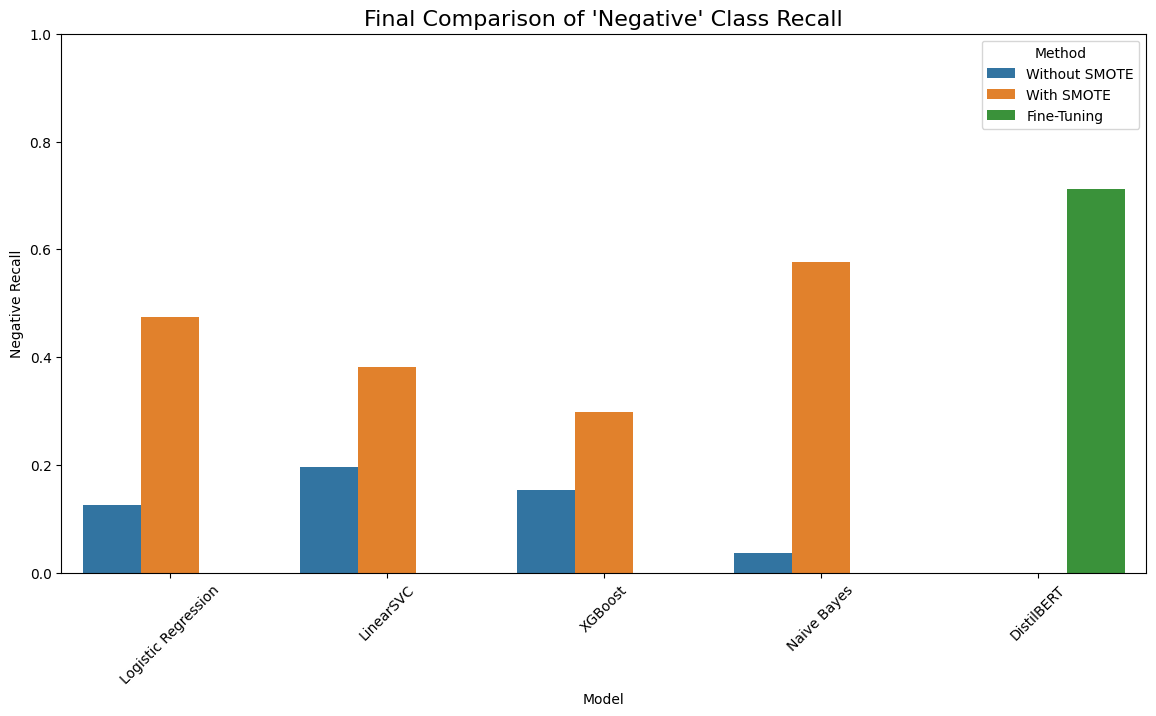

In [ ]:

# --- Plot the Final Negative Recall Comparison ---
plt.figure(figsize=(14, 7))
sns.barplot(data=final_comparison_df, x="Model", y="Negative Recall", hue="Method")
plt.title("Final Comparison of 'Negative' Class Recall", fontsize=16)
plt.xticks(rotation=45)
plt.ylim(0, 1.0) # Adjust ylim for better visibility
plt.show()